# 05 — Concentração do mercado de DNS autoritativo

**Pergunta:** qual o nível de concentração do mercado de DNS autoritativo das maiores empresas do mundo, e como ele varia por bloco de origem (EUA, UE, BRICS, Outros), país, setor e porte?

**Escopo e decisões metodológicas**
- Apenas **IPv4** (delimitação de escopo).
- **Unidade de análise: a empresa.** Cada empresa distribui peso 1 entre os seus provedores, proporcional ao número de NS de cada um (**atribuição fracionada**). Assim, as participações somam 100% e o HHI é bem definido.
- **Provedor** = grupo econômico controlador (`dp_as_org`, após o de-para). A versão sem de-para é analisada como sensibilidade.
- **Ponderações:** (i) por número de empresas e (ii) por receita (`revenue_ttm`) — a segunda mede quanto da *economia*, e não só das empresas, depende de cada provedor.

**Métricas**
- Participação do provedor *i*: $s_i$. **HHI** $=10{,}000\sum_i s_i^2$.
- **CR$_k$**: soma das participações dos $k$ maiores provedores.
- **Nº efetivo de provedores** $=10{,}000/\text{HHI}$ (quantos provedores de mesmo tamanho gerariam esse HHI).
- Incerteza: **IC 95% por bootstrap de empresas** (1.000 réplicas). Comparações entre blocos: **teste de permutação** sobre a diferença de HHI.

> Referência para leitura do HHI (diretrizes de fusões do DOJ/FTC): faixas em torno de 1.000 e 1.800 costumam separar mercados pouco, moderadamente e altamente concentrados — **confirme a versão vigente antes de citar no paper**. O HHI global mistura mercados distintos (países/idiomas/regulação); por isso os recortes por bloco e país são a leitura principal.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import display

from src.analysis_utils import *

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)
MIN_N = 30   # n mínimo de empresas para um recorte por país

v4, cp, comp = prepare()   # IPv4 -> (empresa, provedor) com peso fracionado -> 1 linha por empresa
print(f"{len(comp):,} empresas | {len(v4):,} linhas IPv4 | {cp['provider'].nunique():,} grupos de provedores")

N_BOOT, N_PERM = 1000, 1000

W, ranks, providers = share_matrix(cp)     # empresas x provedores (pesos fracionados)
meta = comp.loc[ranks]                     # atributos das empresas, na ordem das linhas de W
rev = meta["revenue_ttm"].to_numpy()
ALL = np.arange(W.shape[0])
country_of = cp.drop_duplicates("provider").set_index("provider")["provider_cc"]

10,283 empresas | 44,069 linhas IPv4 | 1,083 grupos de provedores


## 1. Visão global

In [2]:
def summarize(rows, weight=None, label="", W_=None):
    W_ = W if W_ is None else W_
    m = group_metrics(W_, rows, weight)
    ci = bootstrap_metrics(W_, rows, weight, N_BOOT)
    return {"group": label, "n_companies": len(rows), "n_providers": m["n_providers"],
            "HHI": m["HHI"], "HHI_lo": ci["HHI"][0], "HHI_hi": ci["HHI"][1], "N_eff": m["N_eff"],
            "CR1": 100 * m["CR1"], "CR3": 100 * m["CR3"], "CR5": 100 * m["CR5"], "CR10": 100 * m["CR10"]}


glob = pd.DataFrame([summarize(ALL, None, "Companies (count)"),
                     summarize(ALL, rev, "Revenue-weighted")]).set_index("group")
display(glob)
save_table(glob, "conc_global")

,n_companies,n_providers,HHI,HHI_lo,HHI_hi,N_eff,CR1,CR3,CR5,CR10
group,,,,,,,,,,
Companies (count),10283,1083,878.71,850.48,912.53,11.38,22.05,44.39,57.26,69.10
Revenue-weighted,10283,1083,626.17,552.19,725.91,15.97,14.96,36.43,51.14,64.55


,country,share_companies,share_revenue,reach_companies
provider,,,,
"Cloudflare, Inc.",US,22.05,10.97,22.44
"Amazon.com, Inc.",US,13.38,9.58,14.26
Host Europe GmbH,DE,8.96,2.15,9.01
DigiCert,US,7.63,10.51,8.06
Microsoft Corporation,US,5.25,5.13,5.82
Akamai,US,4.99,14.96,5.61
Alibaba,CN,2.53,3.85,2.65
Internet Initiative Japan Inc.,JP,1.65,1.77,1.77
NSONE Inc,US,1.34,3.13,1.64


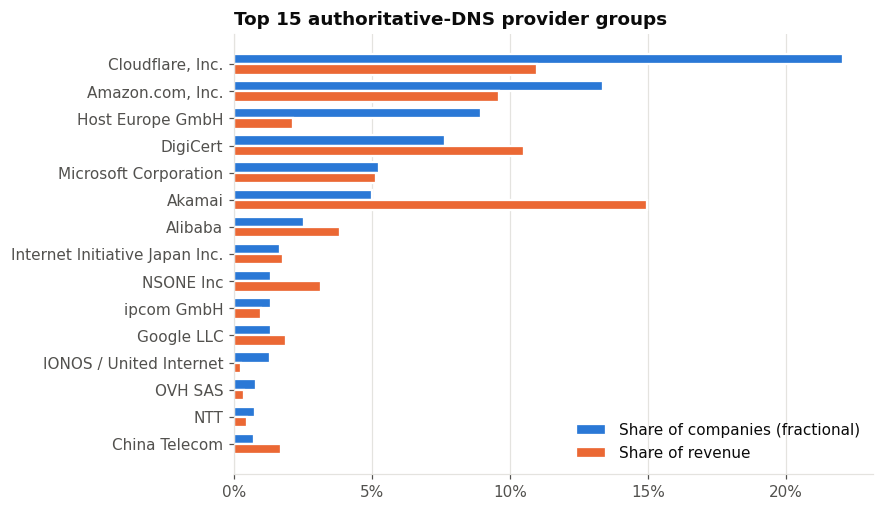

In [3]:
# participação de cada provedor: por empresas (fracionada), por receita e "alcance" (% de empresas que o usam)
share_c = np.asarray(W.sum(axis=0)).ravel() / W.shape[0]
share_r = np.asarray(W.T @ rev).ravel() / rev.sum()
reach = np.asarray((W > 0).sum(axis=0)).ravel() / W.shape[0]
prov = (pd.DataFrame({"country": country_of.reindex(providers).to_numpy(),
                      "share_companies": 100 * share_c, "share_revenue": 100 * share_r,
                      "reach_companies": 100 * reach}, index=providers)
          .sort_values("share_companies", ascending=False))
display(prov.head(15))
save_table(prov.head(50), "conc_top_providers")

top = prov.head(15)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
y, h = np.arange(len(top)), 0.38
ax.barh(y - h / 2, top["share_companies"], h, color="#2a78d6", edgecolor="white", linewidth=1.5,
        label="Share of companies (fractional)")
ax.barh(y + h / 2, top["share_revenue"], h, color="#eb6834", edgecolor="white", linewidth=1.5,
        label="Share of revenue")
ax.set_yticks(y)
ax.set_yticklabels(top.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="y", visible=False)
ax.set_title("Top 15 authoritative-DNS provider groups")
ax.legend(loc="lower right")
save_fig(fig, "fig_conc_top_providers")
plt.show()

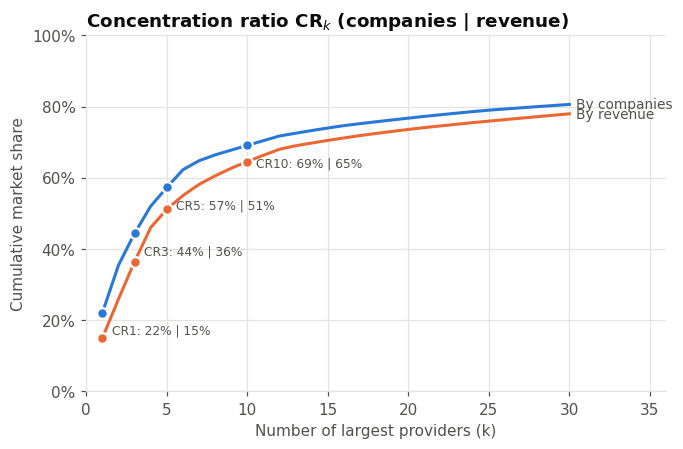

In [4]:
# curva de CR_k: participação acumulada dos k maiores provedores
K = 30
cum_c = 100 * np.cumsum(np.sort(share_c)[::-1])[:K]
cum_r = 100 * np.cumsum(np.sort(share_r)[::-1])[:K]
ks = np.arange(1, K + 1)
mark = [1, 3, 5, 10]

fig, ax = plt.subplots(figsize=(6.8, 4.2))
for cum, color, name in [(cum_c, "#2a78d6", "By companies"), (cum_r, "#eb6834", "By revenue")]:
    ax.plot(ks, cum, color=color, linewidth=2)
    ax.plot(ks[[k - 1 for k in mark]], cum[[k - 1 for k in mark]], "o", color=color,
            markersize=7, markeredgecolor="white", markeredgewidth=1.5)
    ax.text(K + 0.4, cum[-1], name, color=INK2, va="center", fontsize=9)
for k in mark:
    ax.annotate(f"CR{k}: {cum_c[k - 1]:.0f}% | {cum_r[k - 1]:.0f}%", (k, cum_c[k - 1]),
                textcoords="offset points", xytext=(6, -14), fontsize=8, color=INK2)
ax.set_xlim(0, K + 6)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("Number of largest providers (k)")
ax.set_ylabel("Cumulative market share")
ax.set_title("Concentration ratio CR$_k$ (companies | revenue)")
save_fig(fig, "fig_conc_crk_curve")
plt.show()

## 2. Concentração por bloco de origem e por país

n_companies  n_providers      HHI   HHI_lo   HHI_hi  N_eff   CR1   CR3   CR5  CR10
weighting group                                                                                     
count     US             3257          263 1,552.16 1,485.02 1,622.26   6.44 29.22 60.58 77.99 88.59
          EU             1782          394   493.15   455.61   545.36  20.28 15.44 29.18 40.98 58.97
          BRICS          1281          177   903.42   837.27   992.63  11.07 18.70 45.09 59.80 75.92
          Others         3963          456   865.53   817.02   922.11  11.55 21.10 43.34 54.74 68.69
revenue   US             3257          263   951.00   806.49 1,244.33  10.52 19.43 47.09 62.56 77.00
          EU             1782          394   580.20   515.78   777.04  17.24 14.17 35.73 47.57 62.17
          BRICS          1281          177 1,034.20   852.25 1,369.77   9.67 23.51 46.82 61.27 80.38
          Others         3963          456   731.72   623.43   916.91  13.67 16.00 40.69 55.67 66.99

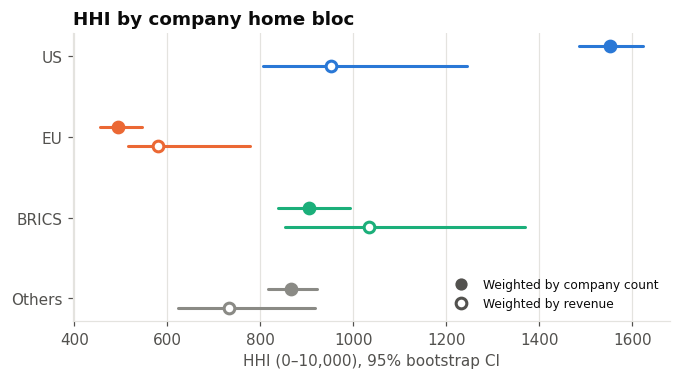

In [5]:
rows_by = {b: np.where(meta["home_bloc"].to_numpy() == b)[0] for b in BLOCS}

bloc_tab = pd.DataFrame(
    [{**summarize(rows_by[b], None, b), "weighting": "count"} for b in BLOCS] +
    [{**summarize(rows_by[b], rev, b), "weighting": "revenue"} for b in BLOCS]
).set_index(["weighting", "group"])
display(bloc_tab)
save_table(bloc_tab, "conc_by_bloc")

fig, ax = plt.subplots(figsize=(7, 3.4))
for off, w, hollow in [(-0.12, "count", False), (0.12, "revenue", True)]:
    t = bloc_tab.loc[w].loc[BLOCS]
    ci_dots(ax, BLOCS, t["HHI"], t["HHI_lo"], t["HHI_hi"], [BLOC_COLOR[b] for b in BLOCS],
            hollow=hollow, offset=off)
ax.invert_yaxis()
ax.set_xlabel("HHI (0–10,000), 95% bootstrap CI")
ax.set_title("HHI by company home bloc")
ax.legend(handles=[plt.Line2D([], [], marker="o", color="none", markerfacecolor=INK2,
                              markeredgecolor=INK2, markersize=7, label="Weighted by company count"),
                   plt.Line2D([], [], marker="o", color="none", markerfacecolor="white",
                              markeredgecolor=INK2, markeredgewidth=2, markersize=7,
                              label="Weighted by revenue")], loc="lower right", fontsize=8)
save_fig(fig, "fig_conc_hhi_bloc")
plt.show()

In [6]:
# testes de permutação entre blocos (HHI por contagem de empresas); Bonferroni para 6 comparações
import itertools
hhi_b = bloc_tab.loc["count"]["HHI"]
res = []
for a, b in itertools.combinations(BLOCS, 2):
    d, p = permutation_hhi_diff(W, rows_by[a], rows_by[b], None, N_PERM)
    res.append({"A": a, "B": b, "HHI_A": hhi_b[a], "HHI_B": hhi_b[b], "diff (A-B)": d,
                "p_perm": p, "p_bonferroni": min(1.0, p * 6)})
perm = pd.DataFrame(res)
display(perm)
save_table(perm.set_index(["A", "B"]), "conc_bloc_permutation")

,A,B,HHI_A,HHI_B,diff (A-B),p_perm,p_bonferroni
0,US,EU,"1,552.16",493.15,"1,059.01",0.00,0.01
1,US,BRICS,"1,552.16",903.42,648.75,0.00,0.01
2,US,Others,"1,552.16",865.53,686.63,0.00,0.01
3,EU,BRICS,493.15,903.42,-410.27,0.00,0.01
4,EU,Others,493.15,865.53,-372.38,0.00,0.01
5,BRICS,Others,903.42,865.53,37.89,0.45,1.00


,n_companies,n_providers,HHI,HHI_lo,HHI_hi,N_eff,CR1,CR3,CR5,CR10,home_bloc
group,,,,,,,,,,,
IL,173,22,"2,976.40","2,386.15","3,737.30",3.36,52.08,69.36,80.35,92.33,Others
CN,483,39,"2,809.03","2,479.49","3,215.72",3.56,49.19,73.15,85.21,94.84,BRICS
NZ,52,10,"2,552.60","1,916.13","3,580.44",3.92,40.38,76.92,88.46,100.00,Others
GR,43,14,"2,391.50","1,739.30","3,633.56",4.18,41.86,72.09,83.72,97.67,EU
KW,118,26,"2,156.38","1,592.73","2,890.73",4.64,42.71,64.76,73.74,86.36,Others
AU,354,40,"1,849.18","1,654.77","2,124.26",5.41,30.23,65.54,81.07,93.39,Others
SA,232,61,"1,758.84","1,429.36","2,242.60",5.69,37.21,59.75,68.67,79.97,Others
AE,45,12,"1,694.92","1,407.27","2,580.58",5.90,28.15,65.93,79.26,95.56,BRICS
CA,386,40,"1,642.45","1,446.61","1,899.67",6.09,31.89,62.01,78.42,89.52,Others


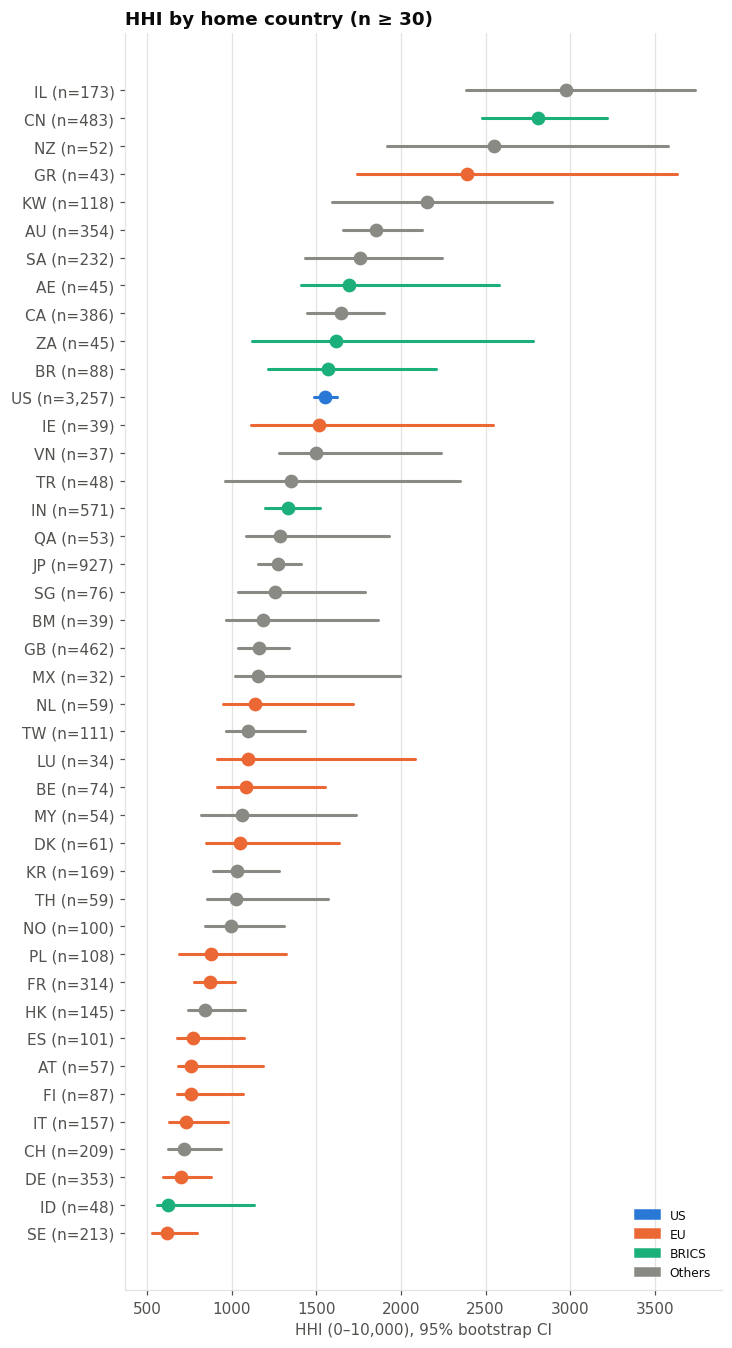

In [7]:
# por país (n >= MIN_N)
cn = meta["home"].value_counts()
countries = cn[cn >= MIN_N].index.tolist()
country_tab = pd.DataFrame(
    [summarize(np.where(meta["home"].to_numpy() == c)[0], None, c) for c in countries]
).set_index("group").join(meta.groupby("home")["home_bloc"].first())
country_tab = country_tab.sort_values("HHI", ascending=False)
display(country_tab)
save_table(country_tab, "conc_by_country")

fig, ax = plt.subplots(figsize=(7, 0.32 * len(country_tab) + 1.4))
ci_dots(ax, [f"{c} (n={int(n):,})" for c, n in zip(country_tab.index, country_tab["n_companies"])],
        country_tab["HHI"], country_tab["HHI_lo"], country_tab["HHI_hi"],
        [BLOC_COLOR[b] for b in country_tab["home_bloc"]])
ax.invert_yaxis()
ax.set_xlabel("HHI (0–10,000), 95% bootstrap CI")
ax.set_title(f"HHI by home country (n ≥ {MIN_N})")
ax.legend(handles=[Patch(color=BLOC_COLOR[b], label=b) for b in BLOCS], loc="lower right", fontsize=8)
save_fig(fig, "fig_conc_hhi_country")
plt.show()

## 3. Porte e setor

,n_companies,n_providers,HHI,HHI_lo,HHI_hi,N_eff,CR1,CR3,CR5,CR10
group,,,,,,,,,,
Top 500,500,169,713.05,621.18,850.07,14.02,18.04,39.56,52.74,66.60
"Top 1,000",1000,275,683.64,622.69,768.45,14.63,15.91,39.22,53.21,66.09
"Top 2,000",2000,471,633.65,592.80,684.71,15.78,12.47,36.17,52.77,64.57
"Top 5,000",5000,758,702.95,671.56,740.79,14.23,15.92,39.95,54.17,67.86
All,10283,1083,878.71,850.48,912.53,11.38,22.05,44.39,57.26,69.10


,n_companies,n_providers,HHI,HHI_lo,HHI_hi,N_eff,CR1,CR3,CR5,CR10
group,,,,,,,,,,
Real Estate,664,155,"1,217.52","1,067.00","1,418.70",8.21,29.07,52.62,64.14,73.08
Healthcare,1075,181,"1,153.13","1,054.73","1,271.40",8.67,23.95,54.08,66.78,75.93
Technology,1277,234,"1,062.49",971.93,"1,175.06",9.41,21.15,48.45,60.76,74.51
Energy,410,112,983.00,845.72,"1,183.60",10.17,20.81,47.36,62.27,71.71
Financial Services,1521,321,962.69,878.09,"1,066.32",10.39,24.55,44.82,60.43,69.46
Communication Services,641,183,950.49,818.60,"1,115.50",10.52,24.81,44.88,53.11,64.60
Consumer Cyclical,1265,238,946.60,857.91,"1,042.45",10.56,22.11,46.23,59.04,72.25
Basic Materials,722,158,887.60,783.56,"1,017.11",11.27,22.58,45.21,58.52,67.71
Consumer Defensive,616,142,869.40,770.06,"1,012.09",11.50,21.39,43.30,59.09,70.95


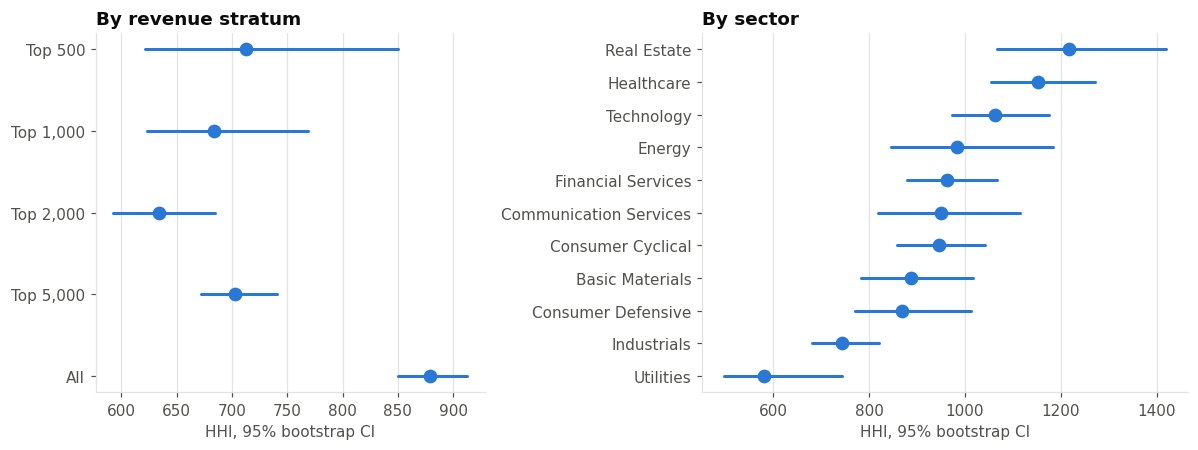

In [8]:
rr = meta["rev_rank"].to_numpy()
strata = {"Top 500": 500, "Top 1,000": 1000, "Top 2,000": 2000, "Top 5,000": 5000, "All": 10**9}
strata_tab = pd.DataFrame([summarize(np.where(rr <= n)[0], None, k) for k, n in strata.items()]).set_index("group")
display(strata_tab)

sectors = meta["sector"].dropna().unique()
sector_tab = (pd.DataFrame([summarize(np.where(meta["sector"].to_numpy() == s)[0], None, s) for s in sectors])
                .set_index("group").sort_values("HHI", ascending=False))
display(sector_tab)
save_table(strata_tab, "conc_by_revenue_stratum")
save_table(sector_tab, "conc_by_sector")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ci_dots(axes[0], strata_tab.index, strata_tab["HHI"], strata_tab["HHI_lo"], strata_tab["HHI_hi"],
        ["#2a78d6"] * len(strata_tab))
axes[0].invert_yaxis()
axes[0].set_title("By revenue stratum")
axes[0].set_xlabel("HHI, 95% bootstrap CI")
ci_dots(axes[1], sector_tab.index, sector_tab["HHI"], sector_tab["HHI_lo"], sector_tab["HHI_hi"],
        ["#2a78d6"] * len(sector_tab))
axes[1].invert_yaxis()
axes[1].set_title("By sector")
axes[1].set_xlabel("HHI, 95% bootstrap CI")
fig.tight_layout()
save_fig(fig, "fig_conc_hhi_strata_sector")
plt.show()

## 4. Sensibilidade

Quão dependente é o resultado das escolhas metodológicas? O que se espera de um resultado robusto é que a **conclusão qualitativa** (nível de concentração e ranking dos blocos) se mantenha entre as variantes.

In [9]:
variants = {}

# (a) baseline
variants["Baseline (dp_as_org, fractional)"] = (W, ALL, None)

# (b) sem de-para: organização como registrada no ASN
cp_nd = company_provider(v4, "as_org", "as_country_code")
W_nd, r_nd, _ = share_matrix(cp_nd)
variants["No de-para (as_org)"] = (W_nd, np.arange(W_nd.shape[0]), None)

# (c) provedor "dominante" da empresa (o de mais NS), sem fracionar
cp_dom = (cp.sort_values(["rank", "n_ns", "provider"], ascending=[True, False, True])
            .drop_duplicates("rank").assign(weight=1.0))
W_dom, _, _ = share_matrix(cp_dom)
variants["Dominant provider only"] = (W_dom, np.arange(W_dom.shape[0]), None)

# (d) provedor identificado pelo domínio do NS (nível de nome, não de rede)
cp_ns = company_provider(v4, "ns_apex", "dp_as_country_code")
W_ns, _, _ = share_matrix(cp_ns)
variants["NS domain (ns_apex)"] = (W_ns, np.arange(W_ns.shape[0]), None)

# (e) ponderado por receita, sem as empresas com receita < US$ 1 milhão (suspeitas)
ok = np.where(rev >= 1e6)[0]
variants["Revenue-weighted, revenue ≥ US$1M"] = (W, ok, rev)
variants["Revenue-weighted (baseline)"] = (W, ALL, rev)

sens = pd.DataFrame([summarize(r, w, k, W_=W_) for k, (W_, r, w) in variants.items()]).set_index("group")
display(sens)
save_table(sens, "conc_sensitivity")

,n_companies,n_providers,HHI,HHI_lo,HHI_hi,N_eff,CR1,CR3,CR5,CR10
group,,,,,,,,,,
"Baseline (dp_as_org, fractional)",10283,1083,878.71,850.48,912.53,11.38,22.05,44.39,57.26,69.10
No de-para (as_org),10283,1276,846.60,817.42,881.60,11.81,22.05,44.39,55.17,66.35
Dominant provider only,10283,828,885.40,857.04,919.76,11.29,22.05,44.57,57.46,69.58
NS domain (ns_apex),10283,2661,378.85,356.32,401.71,26.40,15.84,29.02,34.41,40.64
"Revenue-weighted, revenue ≥ US$1M",10126,1078,626.17,554.09,730.58,15.97,14.96,36.43,51.14,64.55
Revenue-weighted (baseline),10283,1083,626.17,552.19,725.91,15.97,14.96,36.43,51.14,64.55


## 5. Como ler e reportar

- Reporte o **HHI e o CR$_k$ globais** (contagem e receita) com IC, e use o nº efetivo de provedores como tradução intuitiva.
- A tabela por bloco/país responde *onde* a concentração está; o teste de permutação diz se a diferença entre blocos é maior do que a esperada ao acaso (**atenção:** com milhares de empresas, diferenças pequenas ficam "significativas" — discuta também o tamanho da diferença).
- **Limitação:** o HHI mede concentração entre *grupos controladores* de ASN; provedores *anycast* (Cloudflare, Akamai) operam globalmente, e o país do ASN reflete a jurisdição do controlador, não a localização dos servidores.
- Figuras em `outputs/figures/` (PNG e PDF) e tabelas em `data/analysis/`.